In [54]:
import seaborn as sns
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency
import joypy
from matplotlib import cm

#налаштування стилю графіків
sns.set_theme(style="darkgrid")
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

#  Зміст

* [1. Вступ та опис датасету](#section-1)
  * [1.1. Назва, призначення та джерело даних](#section-1-1)
  * [1.2. Опис набору даних](#section-1-2)
* [2. Розвідувальний аналіз даних (EDA)](#section-2)
  * [2.1. Очищення даних та попередня обробка](#section-2-1)
  * [2.2. Статистичний аналіз](#section-2-2)
  * [2.3. Аналіз взаємозв'язків](#section-2-3)
* [3. Візуалізація даних](#section-3)

## <a id="section-1"></a>1. Вступ та опис датасету

### <a id="section-1-1"></a>1.1. Назва, призначення та джерело даних

- Назва датасету: Credit Risk Dataset.

- Призначення датасету: набір даних використовується для аналізу фінансового стану клієнтів та оцінки ризиків банківського кредитування.

- Джерело даних: відкрита платформа для аналізу даних та машинного навчання Kaggle.

- Посилання для завантаження:
https://www.kaggle.com/datasets/reyazraiyana/credit-risk-dataset?select=credit+risk+dataset.csv


### <a id="section-1-2"></a>1.2. Опис набору даних

Оригінальний набір даних містить 32581 запис та 12 атрибутів. Відповідно до вимог щодо обсягу, з оригінального датасету шляхом випадкового відбору було сформовано робочу вибірку обсягом 5000 рядків.

In [10]:
df = pd.read_csv('Data/credit_risk_dataset.csv')
print("=== РОЗМІРНІСТЬ ДАТАСЕТУ ===")
print(f"{df.shape[0]} рядків, {df.shape[1]} стовпчиків\n")

=== РОЗМІРНІСТЬ ДАТАСЕТУ ===
5000 рядків, 12 стовпчиків



In [9]:
# повна таблиця атрибутів
column_info = pd.DataFrame({
    'Назва атрибута': df.columns,
    'Тип даних': df.dtypes.astype(str).values,
    'Кількість заповнених': df.notnull().sum().values,
    'Пропущені значення': df.isnull().sum().values,
    'Унікальні значення': [df[col].nunique() for col in df.columns]
})

display(column_info)

,Назва атрибута,Тип даних,Кількість заповнених,Пропущені значення,Унікальні значення
0,person_age,int64,5000,0,48
1,person_income,int64,5000,0,1167
2,person_home_ownership,str,5000,0,4
3,person_emp_length,float64,4864,136,28
4,loan_intent,str,5000,0,6
5,loan_grade,str,5000,0,7
6,loan_amnt,int64,5000,0,386
7,loan_int_rate,float64,4516,484,272
8,loan_percent_income,float64,5000,0,67
9,cb_person_default_on_file,str,5000,0,2


##### Таблиця 1.1 — Числові атрибути

| Назва атрибута | Тип даних | Опис та значення |
| :--- | :---: | :--- |
| **`person_age`** | `int64` | Вік позичальника (у роках) |
| **`person_income`** | `int64` | Річний дохід позичальника (у грошових одиницях USD) |
| **`person_emp_length`** | `float64` | Офіційний трудовий стаж позичальника (у роках) |
| **`loan_amnt`** | `int64` | Запитувана сума кредиту |
| **`loan_int_rate`** | `float64` | Процентна ставка за кредитом (у відсотках %) |
| **`loan_percent_income`** | `float64` | Відношення суми кредиту до річного доходу (від 0.0 до 1.0) |
| **`cb_person_cred_hist_length`** | `int64` | Тривалість кредитної історії позичальника (у роках) |

---

##### Таблиця 1.2 — Категоріальні атрибути

| Назва атрибута | Тип даних | Категорії | Опис та значення |
| :--- | :---: | :--- | :--- |
| **`person_home_ownership`** | `object` | `RENT`, `MORTGAGE`, `OWN`, `OTHER` | Оренда житла, іпотека, власна нерухомість, інше |
| **`loan_intent`** | `object` | `PERSONAL`, `EDUCATION`, `MEDICAL`, `VENTURE`, `HOMEIMPROVEMENT`, `DEBTCONSOLIDATION` | Особисті потреби, навчання, медицина, бізнес/стартап, ремонт, консолідація боргів |
| **`loan_grade`** | `object` | `A`, `B`, `C`, `D`, `E`, `F`, `G` | Клас ризику за шкалою банку: A — найменший ризик, G — найвищий |
| **`cb_person_default_on_file`** | `object` | `Y`, `N` | `Y` — є дані про минулі дефолти;<br>`N` — чиста історія |

---

##### Таблиця 1.3 — Цільовий атрибут

| Назва атрибута | Тип даних | Значення мітки | Опис та значення |
| :--- | :---: | :---: | :--- |
| **`loan_status`** | `int64` | `0`, `1` | **`0`** — надійний позичальник (кредит виплачено);<br>**`1`** — ризиковий позичальник (дефолт) |

Візуалізація розподілу цільової змінної

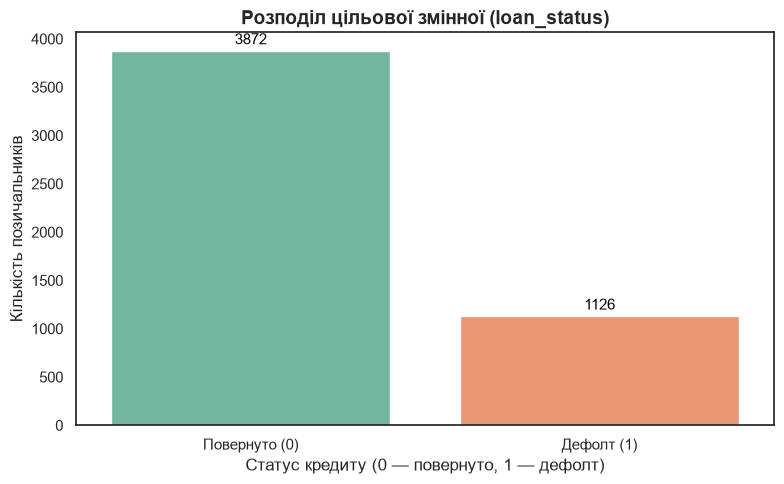

In [45]:
plt.figure(figsize=(8, 5))
ax = sns.countplot(
    data=df,
    x='loan_status',
    hue='loan_status',
    palette='Set2',
    legend=False
)

plt.title('Розподіл цільової змінної (loan_status)', fontsize=14, fontweight='bold')
plt.xlabel('Статус кредиту (0 — повернуто, 1 — дефолт)', fontsize=12)
plt.ylabel('Кількість позичальників', fontsize=12)
plt.xticks([0, 1], ['Повернуто (0)', 'Дефолт (1)'])

for p in ax.patches:
    ax.annotate(
        f'{int(p.get_height())}',
        (p.get_x() + p.get_width() / 2., p.get_height()),
        ha='center', va='baseline',
        fontsize=11, color='black',
        xytext=(0, 5), textcoords='offset points'
    )

plt.tight_layout()
plt.show()

Бачимо, що в цільовій змінній пристуній дисбаланс, дефолних випадків приблизно втричі менше


## <a id="section-2"></a>2. Розвідувальний аналіз даних (EDA)

### <a id="section-2-1"></a>2.1. Очищення даних та попередня обробка

#### 1. Аналіз та обрбка пропущених значень (Missing Values)

Під час виведення інформації про атрибути датасету були пропуски у двох числових атрибутах:

| Назва атрибута | Кількість пропусків | Відсоток пропусків (%) |
| :--- | :---: | :---: |
| **`person_emp_length`** (Трудовий стаж) | 136 | 2.72% |
| **`loan_int_rate`** (Відсоткова ставка) | 484 | 9.68% |


У банківській сфері та фінансовому аналізі штучне заповнення даних (наприклад, заповнення медіаною чи середнім значенням) без підтвердженої методології може призвести до викривлення первинного розподілу та спотворення даних

З огляду на це прийнято:
1. Пропущені значення (`NaN`) у стовпцях `person_emp_length` та `loan_int_rate` залишаються без змін
2. **Створення індикаторів відсутності даних:** для кожного з цих стовпчиків формуються додаткові бінарні прапорці (`person_emp_length_is_missing` та `loan_int_rate_is_missing`). Вони фіксують сам факт відсутності інформації (`1` - дані відсутні, `0` - дані присутні)


In [15]:
df['person_emp_length_is_missing'] = df['person_emp_length'].isnull().astype(int)
df['loan_int_rate_is_missing'] = df['loan_int_rate'].isnull().astype(int)

#### 2. Пошук та видалення аномалій і дублікатів

In [20]:
# 1. ДУБЛІКАТИ
#знаходимо всі рядки, які мають хоча б один повний дублікат
#(keep=False показує і оригінал, і його копію)
duplicates_df = df[df.duplicated(keep=False)].sort_values(by=['person_age', 'person_income', 'loan_amnt'])

print(f"=== ЗНАЙДЕНО ДУБЛЬОВАНИХ РЯДКІВ: {len(duplicates_df)} ===")

if len(duplicates_df) > 0:
    print("Приклади:")
    display(duplicates_df.head(10))
else:
    print("немає")

=== ЗНАЙДЕНО ДУБЛЬОВАНИХ РЯДКІВ: 10 ===
Приклади:


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length,loan_status,person_emp_length_is_missing,loan_int_rate_is_missing
3732,21,27600,RENT,4.0,EDUCATION,A,7500,6.76,0.27,N,4,0,0,0
3947,21,27600,RENT,4.0,EDUCATION,A,7500,6.76,0.27,N,4,0,0,0
2328,23,90000,MORTGAGE,1.0,EDUCATION,B,12000,12.18,0.13,N,4,0,0,0
4179,23,90000,MORTGAGE,1.0,EDUCATION,B,12000,12.18,0.13,N,4,0,0,0
3716,24,33321,OWN,4.0,VENTURE,C,12250,13.11,0.37,Y,4,0,0,0
3894,24,33321,OWN,4.0,VENTURE,C,12250,13.11,0.37,Y,4,0,0,0
1269,27,100000,MORTGAGE,11.0,PERSONAL,A,14400,NaN,0.14,N,8,0,0,1
3767,27,100000,MORTGAGE,11.0,PERSONAL,A,14400,NaN,0.14,N,8,0,0,1
354,28,33600,MORTGAGE,12.0,MEDICAL,A,3000,5.42,0.09,N,5,0,0,0
402,28,33600,MORTGAGE,12.0,MEDICAL,A,3000,5.42,0.09,N,5,0,0,0


Перевірку на дублікати було здійснено, щоб побачити загальну картину унікальності даних, і як бачимо кількість дублікатів мала.
В цьому випадку не будемо їх видаляти, оскільки в нас немає конкретної інформації, яка б свідчила що це помилкові дублікати (наприклад при вивантаженні бази даних). Тут дійсно може бути, що два різних позичальники мають однаковий вік, дохід та інше, оскільки атрибути є досить загальними

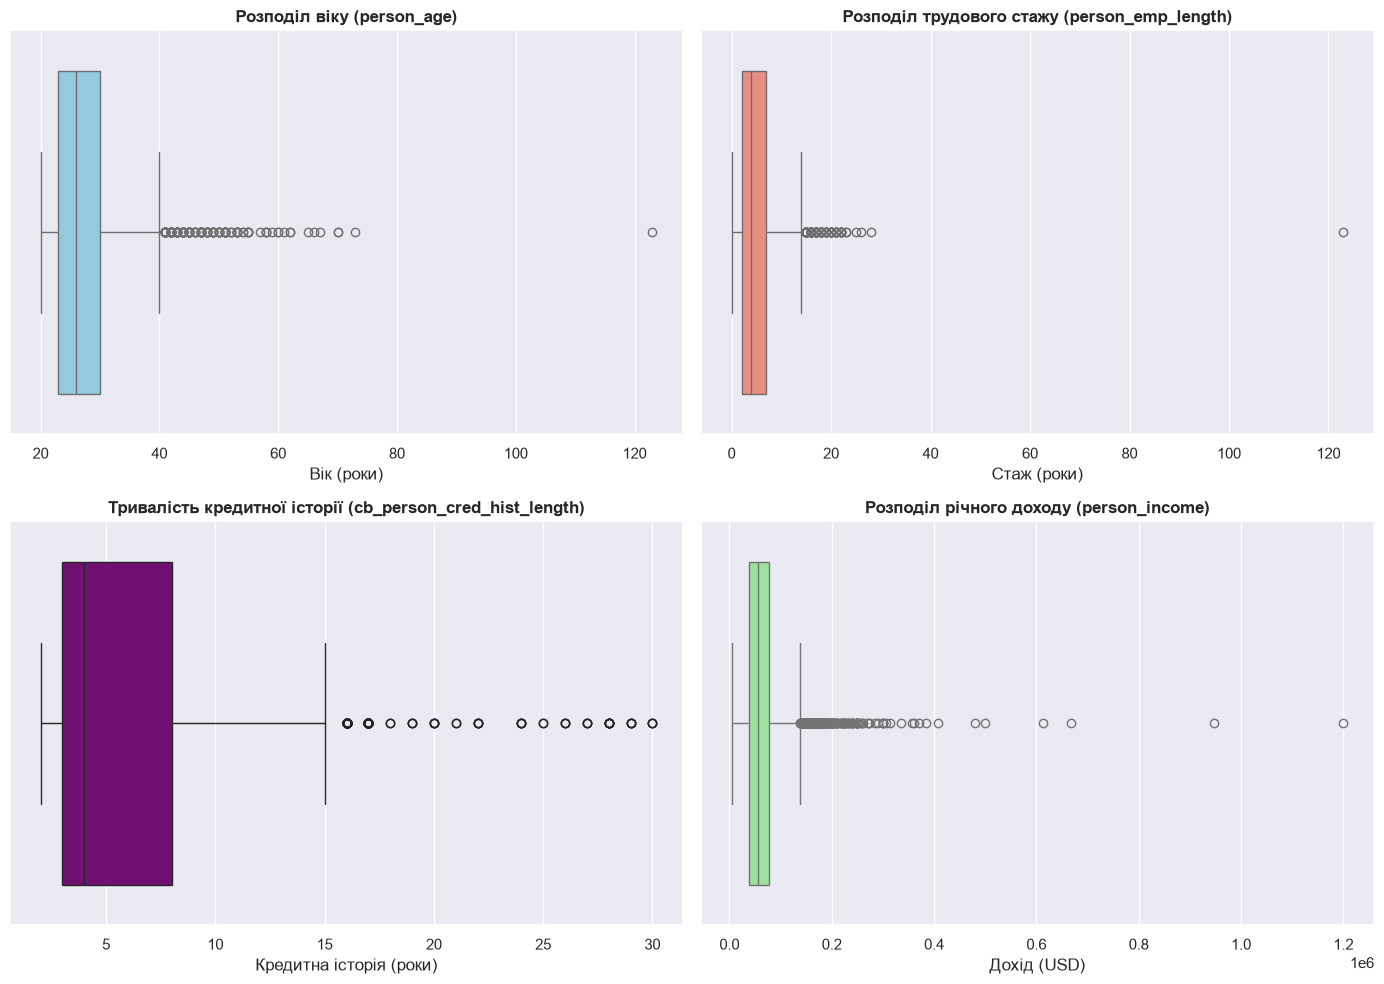

In [24]:
# 2. ВІЗУАЛІЗАЦІЯ ВИКИДІВ
# =========================================================
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Графік 1: вік
sns.boxplot(ax=axes[0, 0], x=df['person_age'], color='skyblue')
axes[0, 0].set_title('Розподіл віку (person_age)', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Вік (роки)')

# Графік 2: стаж
sns.boxplot(ax=axes[0, 1], x=df['person_emp_length'], color='salmon')
axes[0, 1].set_title('Розподіл трудового стажу (person_emp_length)', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('Стаж (роки)')

# Графік 3: тривалість кредитної історії (cb_person_cred_hist_length)
sns.boxplot(ax=axes[1, 0], x=df['cb_person_cred_hist_length'], color='purple')
axes[1, 0].set_title('Тривалість кредитної історії (cb_person_cred_hist_length)', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Кредитна історія (роки)')

# Графік 4: річний дохід
sns.boxplot(ax=axes[1, 1], x=df['person_income'], color='lightgreen')
axes[1, 1].set_title('Розподіл річного доходу (person_income)', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('Дохід (USD)')

plt.tight_layout()
plt.show()

Бачимо присутні викиди:

- **Вік (person_age)** та **Стаж (person_emp_length)**: тут присутні явні помилки введення даних, бо такі значення не можливі, прибераєм

- **Тривалість кредитної історії (cb_person_cred_hist_length)** та **Дохід (person_income)**: тут вже викиди нормальні, у випадку з доходом це можливо

In [25]:
#залишаємо лише фізично можливі значення
df = df[(df['person_age'] <= 100) & (df['person_emp_length'].isna() | (df['person_emp_length'] <= 90))].copy()

#### 3. Кодування категоріальних змінних (Categorical Encoding)

Для підготовки категоріальних текстових ознак до використання в алгоритмах кластеризації два підходи залежно від природи даних:

1. **Ordinal Encoding (Порядкове кодування):**
   * **`loan_grade`**: Має чітку ієрархію ризику ($A \rightarrow 0, B \rightarrow 1, \dots, G \rightarrow 6$).
   * **`cb_person_default_on_file`**: Перетворено у бінарний прапорець ($N \rightarrow 0, Y \rightarrow 1$).

2. **One-Hot Encoding:**
   * **`person_home_ownership`** та **`loan_intent`**: Не мають внутрішнього порядку, тому перетворені на окремі бінарні стовпці ($0$ або $1$) за допомогою `pd.get_dummies()`.

In [26]:
# =========================================================
# КОДУВАННЯ КАТЕГОРІАЛЬНИХ ЗМІННИХ
# =========================================================

#створюємо копію датасету для кодування
df_encoded = df.copy()

# 1. ORDINAL ENCODING

# мапінг (A -> 0 ... G -> 6)
grade_mapping = {'A': 0, 'B': 1, 'C': 2, 'D': 3, 'E': 4, 'F': 5, 'G': 6}
df_encoded['loan_grade'] = df_encoded['loan_grade'].map(grade_mapping)

# мапінг для дефолту в історії (N -> 0, Y -> 1)
default_mapping = {'N': 0, 'Y': 1}
df_encoded['cb_person_default_on_file'] = df_encoded['cb_person_default_on_file'].map(default_mapping)

# 2. ONE-HOT ENCODING (Для номінальних категорій)

df_encoded = pd.get_dummies(
    df_encoded,
    columns=['person_home_ownership', 'loan_intent'],
    dtype=int
)

#  результати кодування
print("=== РОЗМІРНІСТЬ ДАТАСЕТУ ПІСЛЯ КОДУВАННЯ ===")
print(f"Початкова кількість стовпчиків: {df.shape[1]}")
print(f"Нова кількість стовпчиків: {df_encoded.shape[1]}\n")

print("=== ПРИКЛАД КОДОВАНИХ ДАНИХ ===")
display(df_encoded.head())

=== РОЗМІРНІСТЬ ДАТАСЕТУ ПІСЛЯ КОДУВАННЯ ===
Початкова кількість стовпчиків: 14
Нова кількість стовпчиків: 22

=== ПРИКЛАД КОДОВАНИХ ДАНИХ ===


,person_age,person_income,person_emp_length,loan_grade,loan_amnt,loan_int_rate,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length,loan_status,person_emp_length_is_missing,loan_int_rate_is_missing,person_home_ownership_MORTGAGE,person_home_ownership_OTHER,person_home_ownership_OWN,person_home_ownership_RENT,loan_intent_DEBTCONSOLIDATION,loan_intent_EDUCATION,loan_intent_HOMEIMPROVEMENT,loan_intent_MEDICAL,loan_intent_PERSONAL,loan_intent_VENTURE
0,24,28000,6.0,1,10000,10.37,0.36,0,2,0,0,0,0,0,1,0,0,0,1,0,0,0
1,27,64000,0.0,2,10000,15.27,0.16,1,10,0,0,0,0,0,0,1,0,0,0,0,1,0
2,26,72000,10.0,3,16000,NaN,0.22,0,3,0,0,1,1,0,0,0,0,1,0,0,0,0
3,23,27996,7.0,0,10000,NaN,0.36,0,2,1,0,1,0,0,0,1,1,0,0,0,0,0
4,30,44500,2.0,4,13000,16.32,0.29,0,6,1,0,0,0,0,0,1,0,0,0,1,0,0


### <a id="section-2-2"></a>2.2. Статистичний аналіз

In [28]:
# =========================================================
# 2.2. СТАТИСТИЧНИЙ АНАЛІЗ ЧИСЛОВИХ АТРИБУТІВ
# =========================================================

numeric_cols = [
    'person_age', 'person_income', 'person_emp_length',
    'loan_amnt', 'loan_int_rate', 'loan_percent_income',
    'cb_person_cred_hist_length'
]

#розрахунок описових статистик
stats_df = df[numeric_cols].describe().T
stats_df['median'] = df[numeric_cols].median()

stats_df = df[numeric_cols].agg(['min', 'mean', 'median', 'std', 'max']).T
stats_df = stats_df.round(2)

print("=== ОСНОВНІ СТАТИСТИЧНІ ПОКАЗНИКИ ===")
display(stats_df)

=== ОСНОВНІ СТАТИСТИЧНІ ПОКАЗНИКИ ===


,min,mean,median,std,max
person_age,20.00,27.59,26.00,6.03,73.00
person_income,4200.00,65044.36,55000.00,46482.27,1200000.00
person_emp_length,0.00,4.77,4.00,4.03,28.00
loan_amnt,700.00,9521.46,8000.00,6296.17,35000.00
loan_int_rate,5.42,11.01,10.99,3.28,23.22
loan_percent_income,0.00,0.17,0.15,0.11,0.71
cb_person_cred_hist_length,2.00,5.75,4.00,4.07,30.00


На основі розрахованих описових статистик для числових атрибутів можна побачити:

- **Переважно молоді позичальники**: медіани віку становить 26 років, трудового стажу - 4, кредитна історія - 4
- середнє значення річного доходу було дещо збільшене, оскільки наявні високодохідні клієнти. Тому варто використовувати медіану, оскільки вона не так залежить від викидів як середнє
- **Кредитне навантаження (`loan_percent_income`):** відношення суми кредиту до річного доходу в середньому становить 0.17 (17% від річного доходу). Медіанне значення дорівнює 0.15 (15%), що є помірним рівнем навантаження, проте максимальні значення сягають 0.71 (71%), що свідчить про високий ризик дефолту для окремої групи позичальників

Можемо детальніше розглянути розподілів ключових характеристик кредитного портфеля побудувавши гістограми

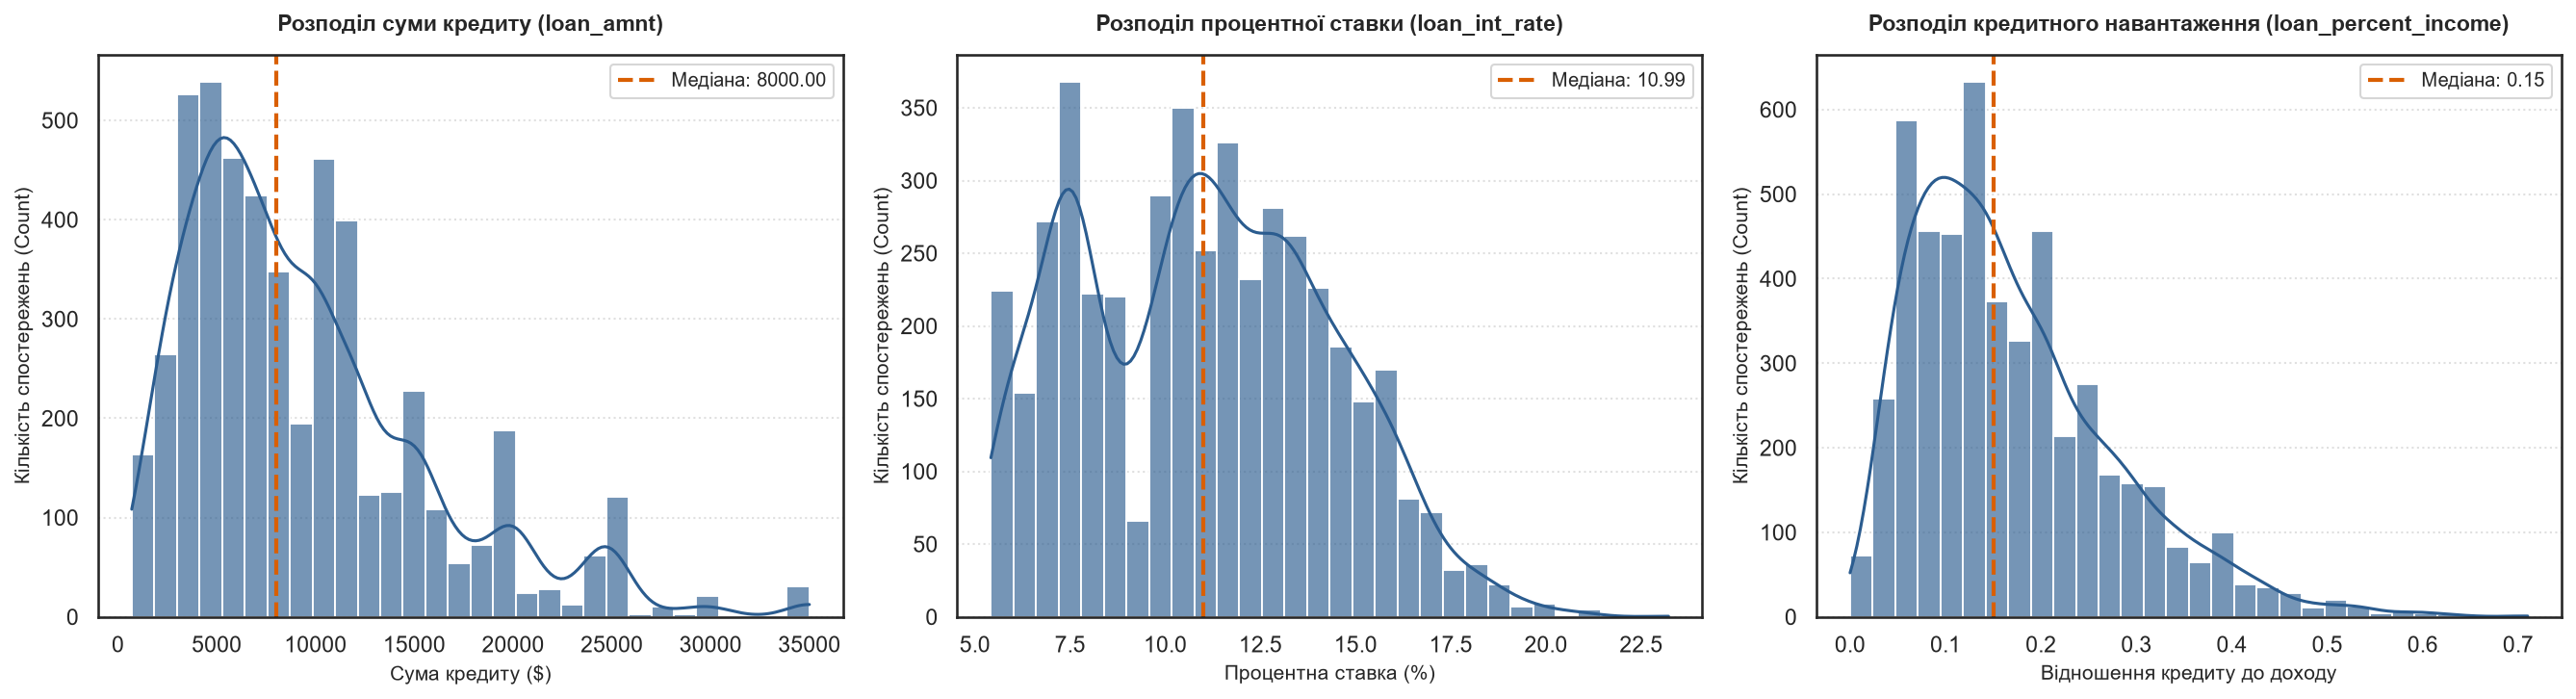

In [41]:

features = ['loan_amnt', 'loan_int_rate', 'loan_percent_income']
titles = ['Розподіл суми кредиту (loan_amnt)',
          'Розподіл процентної ставки (loan_int_rate)',
          'Розподіл кредитного навантаження (loan_percent_income)']
x_labels = ['Сума кредиту ($)', 'Процентна ставка (%)', 'Відношення кредиту до доходу']

fig, axes = plt.subplots(1, 3, figsize=(18, 5), dpi=150)

for i, col in enumerate(features):
    sns.histplot(
        data=df,
        x=col,
        kde=True,
        bins=30,
        ax=axes[i],
        color='#2b5c8f',
        edgecolor='white',
        alpha=0.65
    )

    #розрахунок медіани для нанесення орієнтиру
    median_val = df[col].median()
    axes[i].axvline(median_val, color='#d95f02', linestyle='--', linewidth=2,
                    label=f'Медіана: {median_val:.2f}')

    axes[i].set_title(titles[i], fontsize=11, fontweight='bold', pad=12)
    axes[i].set_xlabel(x_labels[i], fontsize=10)
    axes[i].set_ylabel('Кількість спостережень (Count)', fontsize=10)
    axes[i].legend(loc='upper right', fontsize=9.5)
    axes[i].grid(axis='y', linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

1. **Сума кредиту (`loan_amnt`):**
   * Форма розподілу скошена праворуч
   * Медіанна сума кредиту становить $\$8\,000$


2. **Процентна ставка (`loan_int_rate`):**
   * Форма близька до нормального розподілу з правосторонньою асиметрією
   * Наявність окремих сплесків пояснюється сіткою процентних ставок, жорстко прив'язаних до ризикових грейдів ($A, B, C, D \dots$)


3. **Кредитне навантаження (`loan_percent_income`):**
   * Більшість позичальників мають помірне навантаження (медіана $\approx 0.15$ або $15\%$ від річного доходу). Проте наявний хвіст розподілу, де навантаження сягає $30-50\%+$. саме ця група клієнтів формує основний ризик дефолту.

### <a id="section-2-2"></a>2.3. Аналіз взаємозв'язків

Для дослідження взаємозв'язків було обрано коефіцієнт кореляції Спірмена, оскільки в даних присутні викиди (Пірсон порівнює точні значення, а Спірмен порівнює місця у списку -ранги)

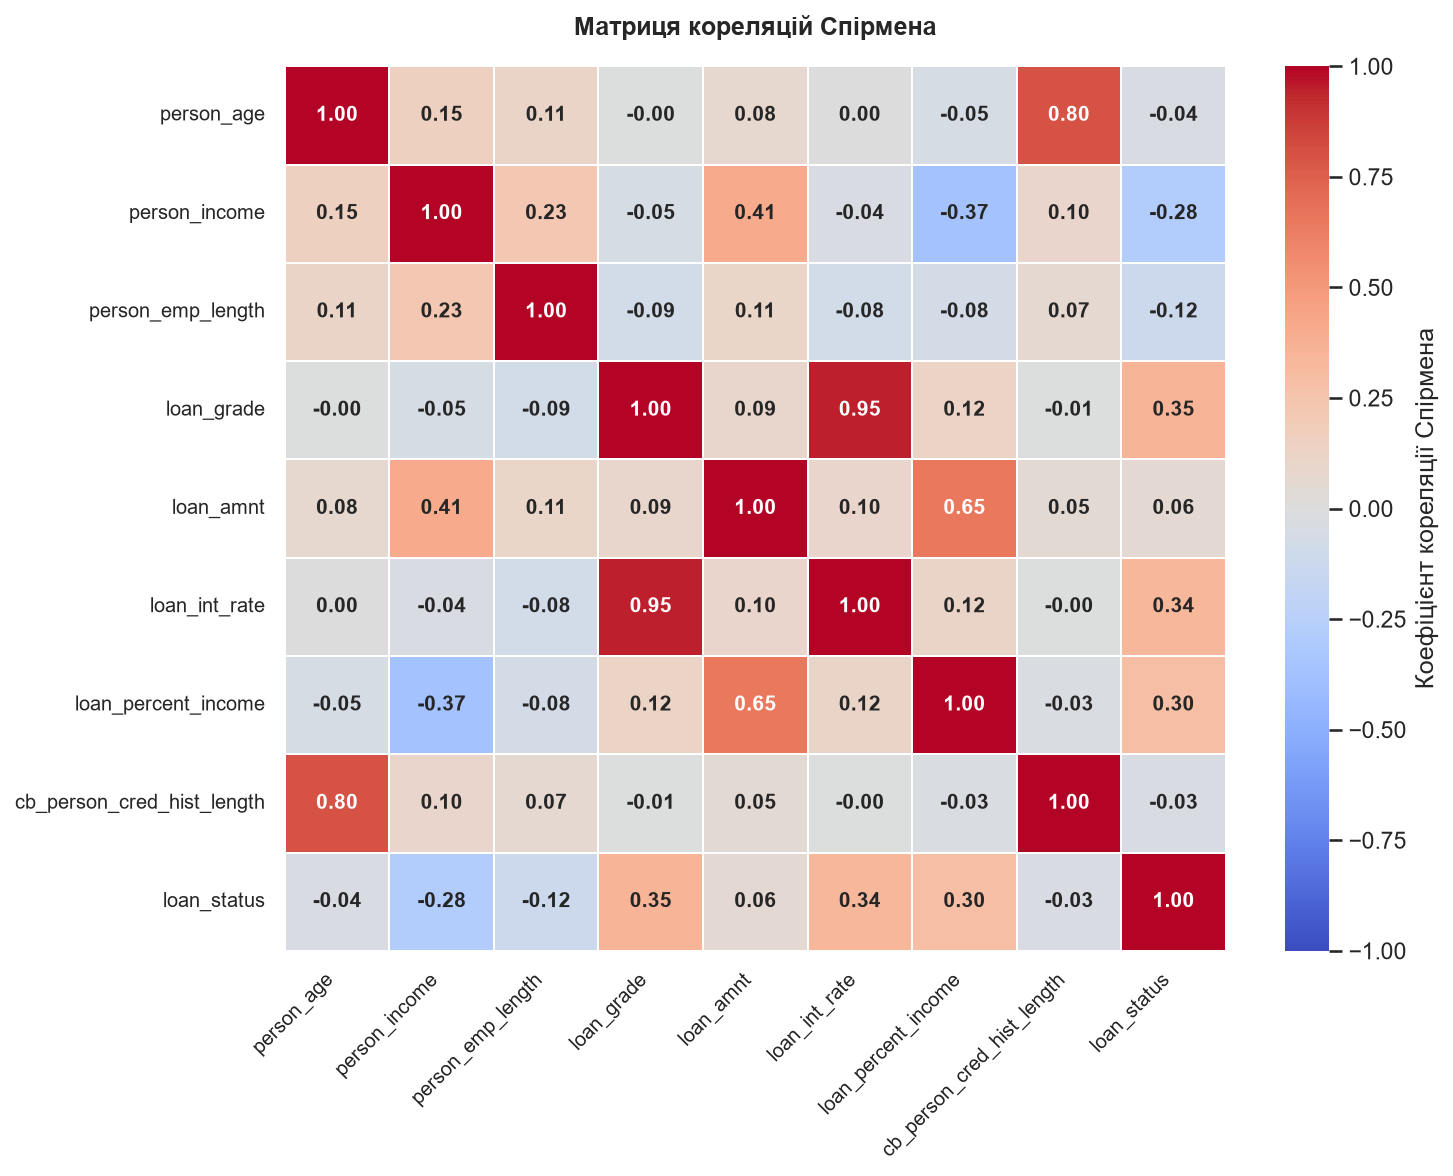

In [34]:
# 1. Відбираємо ЛИШЕ числові та порядкові (рангові) змінні та цільову змінну
numeric_and_ordinal = [
    'person_age', 'person_income', 'person_emp_length',
    'loan_grade', 'loan_amnt', 'loan_int_rate',
    'loan_percent_income', 'cb_person_cred_hist_length', 'loan_status'
]

# розрахунок кореляції Спірмена
corr_clean = df_encoded[numeric_and_ordinal].corr(method='spearman')

plt.figure(figsize=(10, 8), dpi=150)
sns.heatmap(
    corr_clean,
    annot=True,
    fmt=".2f",
    cmap='coolwarm',
    vmin=-1, vmax=1,
    linewidths=0.8,
    linecolor='white',
    annot_kws={"size": 10, "weight": "bold"},
    cbar_kws={"label": "Коефіцієнт кореляції Спірмена"}
)

plt.title("Матриця кореляцій Спірмена", fontsize=12, fontweight='bold', pad=15)
plt.xticks(rotation=45, ha='right', fontsize=9.5)
plt.yticks(fontsize=9.5)
plt.tight_layout()
plt.show()

яНа основі розрахованої матриці бачимо, що:

#### 1. Ключові чинники впливу на ризик дефолту (`loan_status`)
* **Грейд кредиту (`loan_grade`, $r = 0.35$) та Процентна ставка (`loan_int_rate`, $r = 0.34$):** мають найбільший вплив на цільову змінну: чим більший ризиковий грейд та процентна ставка, тим більше неповернення кредиту
* **Відношення кредиту до доходу (`loan_percent_income`, $r = 0.30$):** Високе фінансове навантаження виступає третім за вагомістю фактором ризику.
* **Річний дохід (`person_income`, $r = -0.28$):** демонструє зворотну кореляцію - вищий дохід є головним стримуючим фактором проти дефолту.
* **Трудовий стаж (`person_emp_length`, $r = -0.12$):** триваліший стаж помірно знижує ризик неповернення коштів.
* **Слабкий зв'язок:** Вік (`person_age`, $r = -0.04$), сума кредиту (`loan_amnt`, $r = 0.06$) та тривалість кредитної історії (`cb_person_cred_hist_length`, $r = -0.03$) мають незначний вплив на дефолт у загальній вибірці.

#### 2. Внутрішня дублюваність та мультиколінеарність ($X \leftrightarrow X$)
* **Грейд та Процентна ставка ($r = 0.95$):** дуже сильна кореляція підтверджує, що процентна ставка банку жорстко прив'язана до розрахованого грейду. (важливо пам'ятати про це дублювання, особливо для моделей ML, як-от логістична регресія)
* **Вік та Кредитна історія ($r = 0.80$):** Демонструють дуже високу залежність - старші позичальники мають тривалішу кредитну історію, що є логічним
* **Сума кредиту та Навантаження на дохід ($r = 0.65$):** більша сума кредиту природно збільшує частку кредиту відносно доходу.
* **Сума кредиту та Дохід ($r = 0.41$):** позичальники з вищим доходом зазвичай звертаються за більшими сумами кредитів.

Для зручності ще скористаємось ранжуванням впливу атрибутів на цільові змінну - ризик дефолту loan_status

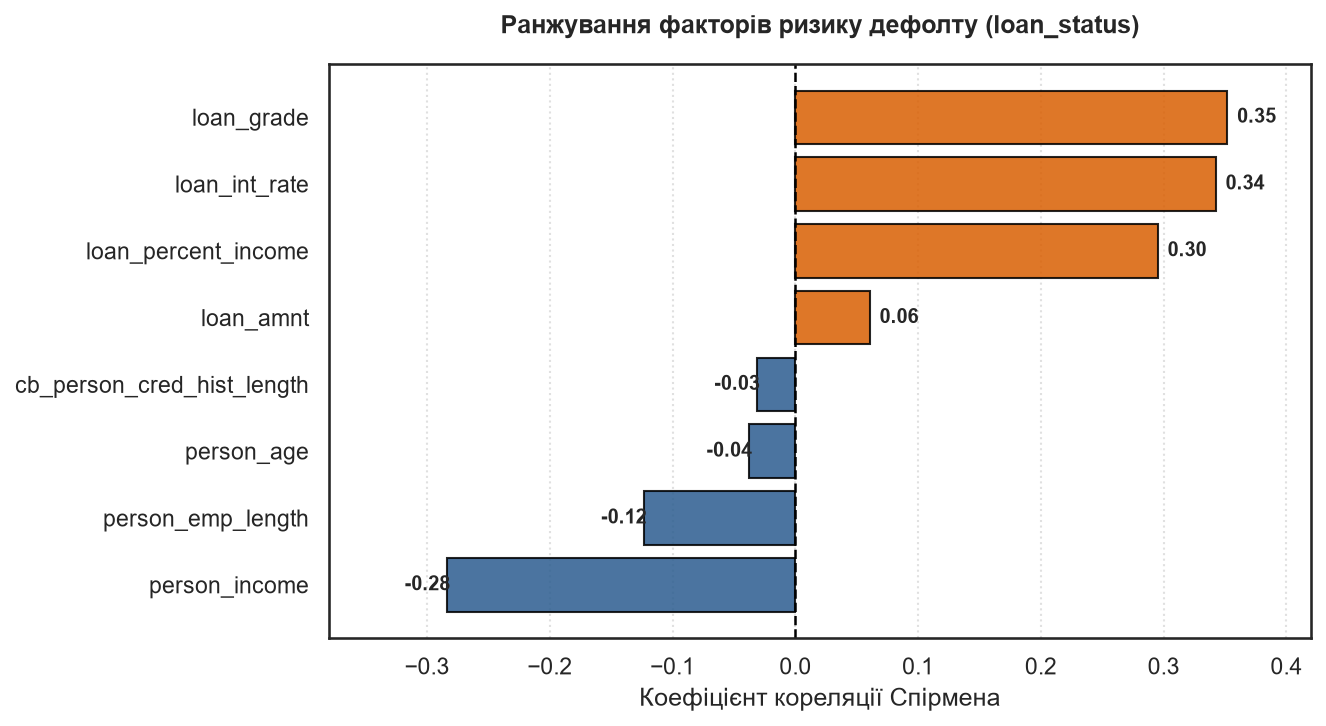

In [36]:
#виділяємо кореляції відносно loan_status та видаляємо самокореляцію
target_corr = corr_clean[['loan_status']].drop(index='loan_status').sort_values(by='loan_status', ascending=True)
plt.figure(figsize=(9, 5), dpi=150)
# оранжевий колір для чинників ризику (r > 0), синій — для захисних чинників (r < 0)
colors = ['#2b5c8f' if val < 0 else '#d95f02' for val in target_corr['loan_status']]
bars = plt.barh(target_corr.index, target_corr['loan_status'], color=colors, edgecolor='black', alpha=0.85)
for bar in bars:
    width = bar.get_width()
    offset = 0.008 if width >= 0 else -0.035
    plt.text(width + offset, bar.get_y() + bar.get_height()/2, f'{width:.2f}',
             va='center', fontsize=9.5, fontweight='bold')

plt.axvline(0, color='black', linewidth=1.2, linestyle='--')
plt.xlim(-0.38, 0.42)
plt.title("Ранжування факторів ризику дефолту (loan_status)", fontsize=12, fontweight='bold', pad=15)
plt.xlabel("Коефіцієнт кореляції Спірмена")
plt.grid(axis='x', linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

Оскільки для звичайної кореляції (Пірсона чи Спірмена) номінальні категоріальні змінні не підходять то скористаємось коефіцієнтом
 Крамера. Він базується на критерії хі-квадрат ($\chi^2$) і показує силу взаємозв'язку між категоріальними ознаками у діапазоні від $0$ (немає зв'язку) до $1$ (повна залежність).

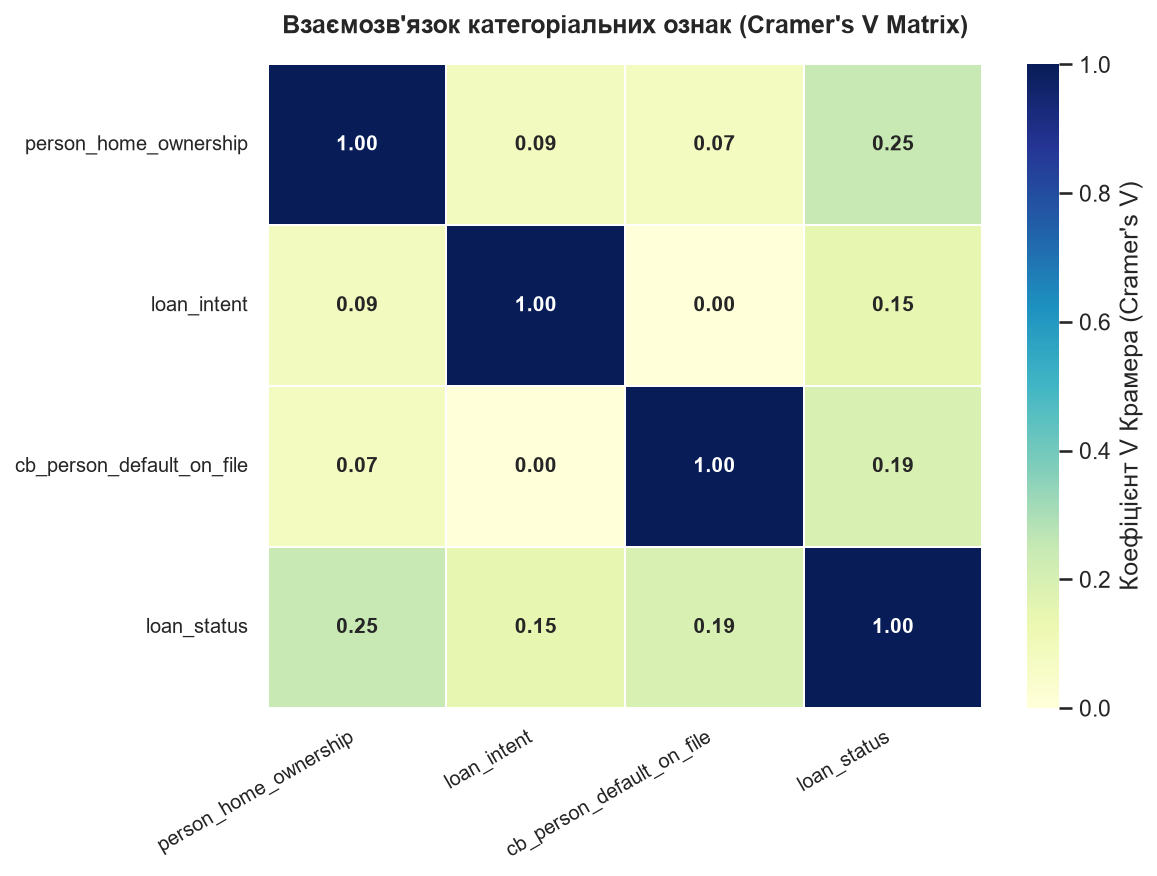

In [39]:
def cramers_v(x, y):
    """Обчислення коефіцієнта V Крамера для двох категоріальних змінних"""
    confusion_matrix = pd.crosstab(x, y)
    chi2 = chi2_contingency(confusion_matrix)[0]
    n = confusion_matrix.sum().sum()
    phi2 = chi2 / n
    r, k = confusion_matrix.shape

    #корекція для зменшення зсуву на малих вибірках або великих таблицях
    phi2corr = max(0, phi2 - ((k-1)*(r-1)) / (n-1))
    rcorr = r - ((r-1)**2) / (n-1)
    kcorr = k - ((k-1)**2) / (n-1)

    denom = min((kcorr-1), (rcorr-1))
    if denom == 0:
        return 0
    return np.sqrt(phi2corr / denom)

# категоріальні та цільової змінної
cat_cols = ['person_home_ownership', 'loan_intent', 'cb_person_default_on_file', 'loan_status']

# формування матриці Cramer's V
cramer_matrix = pd.DataFrame(index=cat_cols, columns=cat_cols, dtype=float)

for col1 in cat_cols:
    for col2 in cat_cols:
        cramer_matrix.loc[col1, col2] = cramers_v(df[col1], df[col2])

# побудова теплокарти Cramer's V
plt.figure(figsize=(8, 6), dpi=150)

sns.heatmap(
    cramer_matrix,
    annot=True,
    fmt=".2f",
    cmap='YlGnBu',
    vmin=0, vmax=1,
    linewidths=0.8,
    linecolor='white',
    annot_kws={"size": 10, "weight": "bold"},
    cbar_kws={"label": "Коефіцієнт V Крамера (Cramer's V)"}
)

plt.title("Взаємозв'язок категоріальних ознак (Cramer's V Matrix)", fontsize=12, fontweight='bold', pad=15)
plt.xticks(rotation=30, ha='right', fontsize=9.5)
plt.yticks(fontsize=9.5)
plt.tight_layout()
plt.show()

Бачимо, що
   * **Тип житла (`person_home_ownership`, $V = 0.25$):** виступає найважливішим категоріальною ознакою дефолту, що підтверджує чутливість ризику до житлового та майнового стану позичальника.
   * **Наявність дефолтів у минулому (`cb_person_default_on_file`, $V = 0.19$):** впливає на поточну ймовірність неповернення коштів.
   * **Мета кредитування (`loan_intent`, $V = 0.15$):** помірна залежність, підтверджуючи різний рівень ризикованості цілей позики.

## <a id="section-3"></a>3. Візуалізація даних

1. Розглянемо детальніше, яким чином мета кридиту та тип житла впливають на успішність його погашення

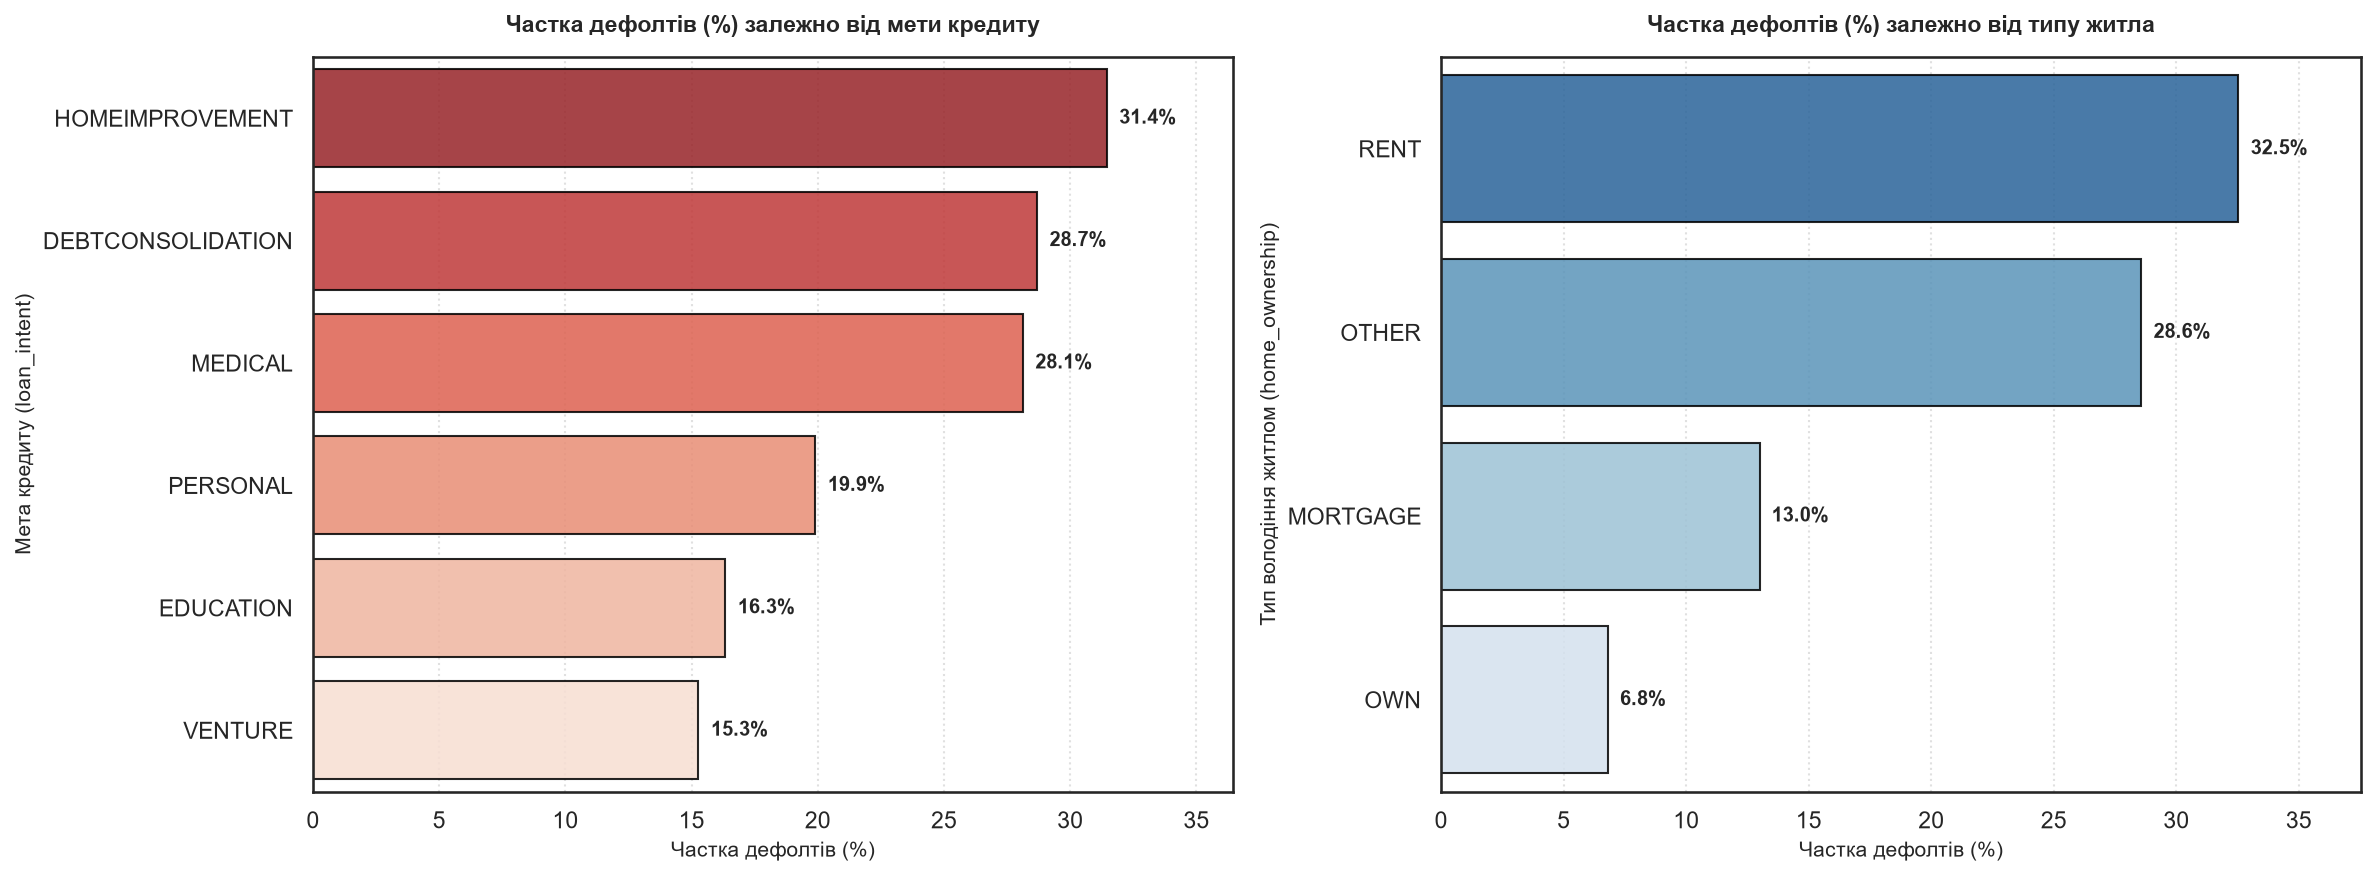

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6), dpi=150)

# ---------------------------------------------------------
# ГРАФІК 1: Default Rate за метою кредиту (loan_intent)
# ---------------------------------------------------------
intent_default = (
    df.groupby('loan_intent')['loan_status']
    .mean()
    .reset_index()
    .sort_values(by='loan_status', ascending=False)
)
intent_default['default_rate_pct'] = intent_default['loan_status'] * 100

bars1 = sns.barplot(
    data=intent_default,
    x='default_rate_pct',
    y='loan_intent',
    hue='loan_intent',
    legend=False,
    ax=axes[0],
    palette='Reds_r',
    edgecolor='black',
    alpha=0.85
)
for bar in bars1.patches:
    width = bar.get_width()
    axes[0].text(width + 0.5, bar.get_y() + bar.get_height()/2, f'{width:.1f}%',
                 va='center', fontsize=9.5, fontweight='bold')

axes[0].set_title("Частка дефолтів (%) залежно від мети кредиту", fontsize=11, fontweight='bold', pad=12)
axes[0].set_xlabel("Частка дефолтів (%)", fontsize=10)
axes[0].set_ylabel("Мета кредиту (loan_intent)", fontsize=10)
axes[0].set_xlim(0, max(intent_default['default_rate_pct']) + 5)
axes[0].grid(axis='x', linestyle=':', alpha=0.6)

# ---------------------------------------------------------
# ГРАФІК 2: Default Rate за типом житла (person_home_ownership)
# ---------------------------------------------------------
home_default = (
    df.groupby('person_home_ownership')['loan_status']
    .mean()
    .reset_index()
    .sort_values(by='loan_status', ascending=False)
)
home_default['default_rate_pct'] = home_default['loan_status'] * 100

bars2 = sns.barplot(
    data=home_default,
    x='default_rate_pct',
    y='person_home_ownership',
    hue='person_home_ownership',
    legend=False,
    ax=axes[1],
    palette='Blues_r',
    edgecolor='black',
    alpha=0.85
)
for bar in bars2.patches:
    width = bar.get_width()
    axes[1].text(width + 0.5, bar.get_y() + bar.get_height()/2, f'{width:.1f}%',
                 va='center', fontsize=9.5, fontweight='bold')

axes[1].set_title("Частка дефолтів (%) залежно від типу житла", fontsize=11, fontweight='bold', pad=12)
axes[1].set_xlabel("Частка дефолтів (%)", fontsize=10)
axes[1].set_ylabel("Тип володіння житлом (home_ownership)", fontsize=10)
axes[1].set_xlim(0, max(home_default['default_rate_pct']) + 5)
axes[1].grid(axis='x', linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

З першого графіку бачимо цікавий результат: найбільшу частку дефолтів мають ті, хто взяли кредит задля ремонту дому.
А от венчурна мета має найменшу частку. Хоча бізнес-проекти потенційно містять високі ризики, низька частка дефолтів свідчить про **сувору банківську перевірку**: банк ретельніше перевіряє бізнес-плани та фінансовий стан таких заявників перед видачею коштів, а самі позичальники виявляють вищий рівень фінансової грамотності.

З другого графіка бачимо, що користувачі, що орендують житло, мають найбільшу частку дефолтів

2. Чи може високий дохід компенсувати високу процентну ставку?

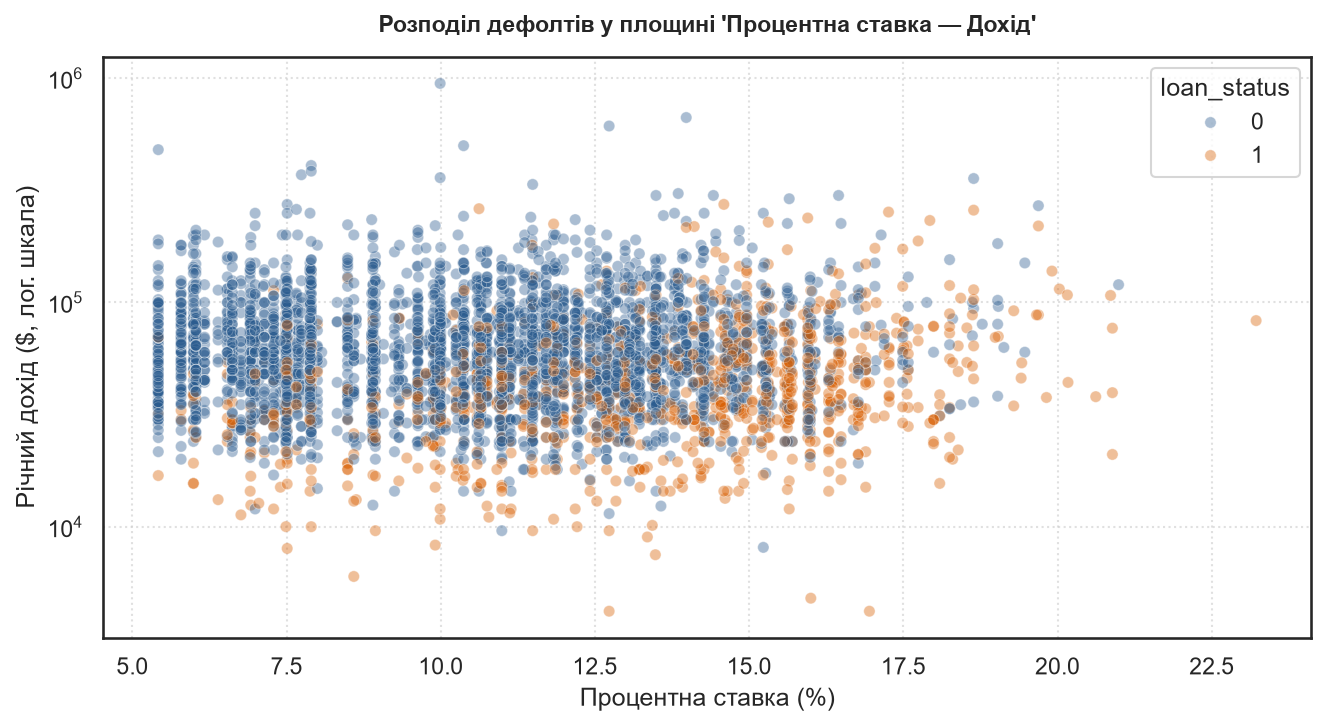

In [47]:
import sns as sns
plt.figure(figsize=(9, 5), dpi=150)

sns.scatterplot(
    data=df,
    x='loan_int_rate',
    y='person_income',
    hue='loan_status',
    palette={0: '#2b5c8f', 1: '#d95f02'},
    alpha=0.4,
    s=30
)

plt.yscale('log')
plt.title("Розподіл дефолтів у площині 'Процентна ставка — Дохід'", fontsize=11, fontweight='bold', pad=12)
plt.xlabel("Процентна ставка (%)")
plt.ylabel("Річний дохід ($, лог. шкала)")
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

 Графік показує, що процентна ставка є агресивнішим чинником дефолту, ніж низький дохід. При перевищенні певної межі вартості кредиту ($15\%+$) ймовірність неповернення коштів різко зростає для всіх сегментів позичальників.
 Це доводить, що занадто дорога ціна кредиту ламає фінансову дисципліну незалежно від статків клієнта.

3. Чи підтверджує кредитна історія ефективність банківського грейду?

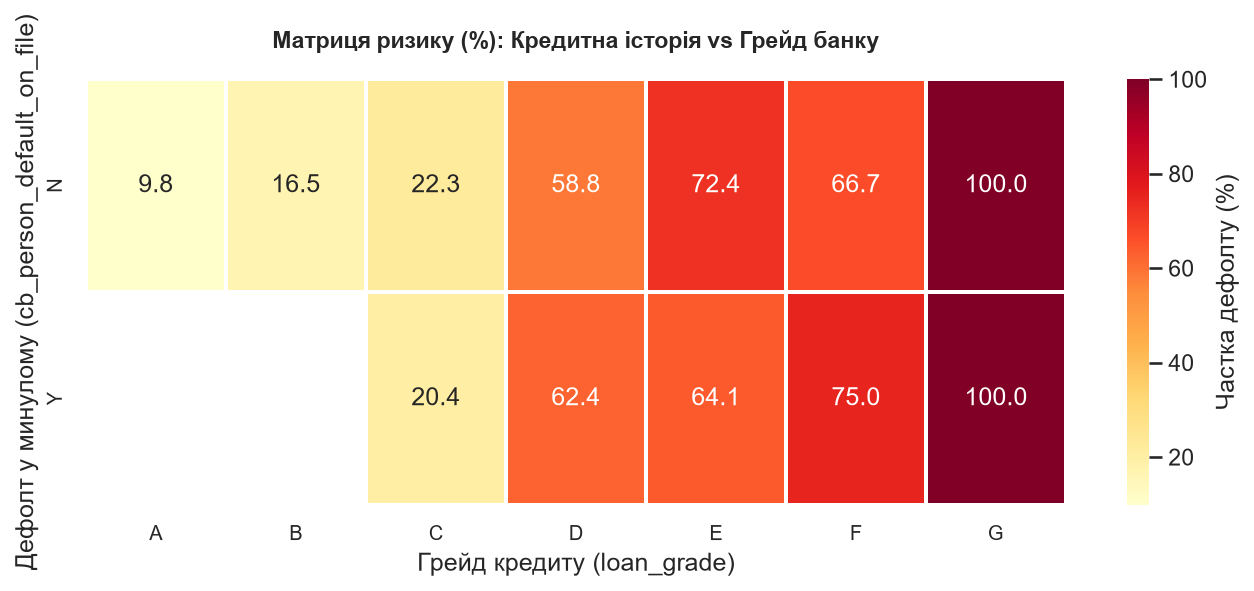

In [48]:
# створюємо зведену таблицю із середнім Default Rate (%)
pivot_risk_matrix = df.pivot_table(
    index='cb_person_default_on_file',
    columns='loan_grade',
    values='loan_status',
    aggfunc='mean'
) * 100

plt.figure(figsize=(9, 4), dpi=150)
sns.heatmap(
    pivot_risk_matrix,
    annot=True,
    fmt=".1f",
    cmap='YlOrRd',
    linewidths=1,
    linecolor='white',
    cbar_kws={'label': 'Частка дефолту (%)'}
)

plt.title("Матриця ризику (%): Кредитна історія vs Грейд банку", fontsize=11, fontweight='bold', pad=15)
plt.xlabel("Грейд кредиту (loan_grade)")
plt.ylabel("Дефолт у минулому (cb_person_default_on_file)")
plt.xticks(fontsize=9.5)
plt.yticks(fontsize=9.5)
plt.tight_layout()
plt.show()

Бачимо, що банк взагалі не дає грейди A і B людям із дефолтами у минулому — мабуть це працює як автоматичний стоп-фактор.

Також бачимо чітку точку зламу на грейді D: до грейду C дефолтність становить близько 20%, а з грейду D вона різко стрибає до 60%+ незалежно від того, чи мав клієнт дефолт раніше. За високої ставки й навантаження поточний кредит ламає платника незалежно від його минулої історії.

4. Перевірка корисності нових ознак: Чи є відсутність даних фактором ризику?

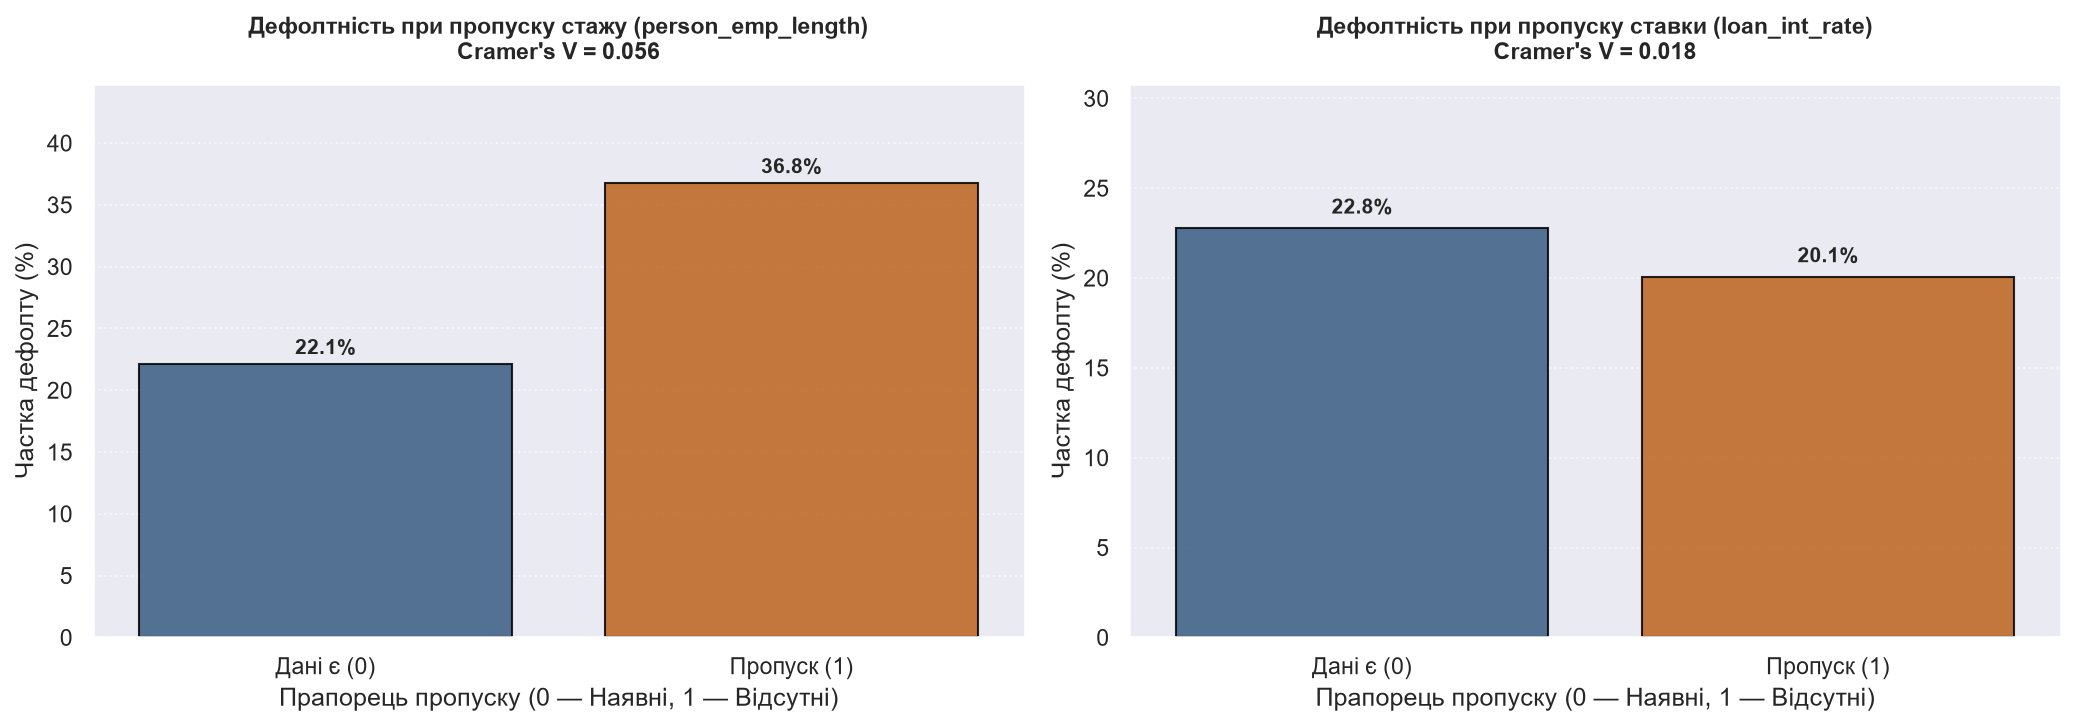

In [57]:
# це ознаки які створили на етапі передобробки
#df['person_emp_length_is_missing'] = df['person_emp_length'].isna().astype(int)
#df['loan_int_rate_is_missing'] = df['loan_int_rate'].isna().astype(int)

# 2. Розрахунок Default Rate для обох факторів
emp_missing_stats = df.groupby('person_emp_length_is_missing')['loan_status'].agg(['mean', 'count']).reset_index()
emp_missing_stats['mean'] *= 100

rate_missing_stats = df.groupby('loan_int_rate_is_missing')['loan_status'].agg(['mean', 'count']).reset_index()
rate_missing_stats['mean'] *= 100

def cramers_v_binary(x, y):
    confusion_matrix = pd.crosstab(x, y)
    chi2 = chi2_contingency(confusion_matrix)[0]
    n = confusion_matrix.sum().sum()
    return np.sqrt(chi2 / (n * (min(confusion_matrix.shape) - 1)))

v_emp = cramers_v_binary(df['person_emp_length_is_missing'], df['loan_status'])
v_rate = cramers_v_binary(df['loan_int_rate_is_missing'], df['loan_status'])
fig, axes = plt.subplots(1, 2, figsize=(14, 5), dpi=150)

bars1 = sns.barplot(
    data=emp_missing_stats,
    x='person_emp_length_is_missing',
    y='mean',
    hue='person_emp_length_is_missing',
    legend=False,
    ax=axes[0],
    palette=['#2b5c8f', '#d95f02'],
    edgecolor='black',
    alpha=0.85
)
for bar in bars1.patches:
    h = bar.get_height()
    if h > 0:
        axes[0].text(bar.get_x() + bar.get_width()/2, h + 0.8, f'{h:.1f}%', ha='center', fontweight='bold', fontsize=10)

axes[0].set_title(f"Дефолтність при пропуску стажу (person_emp_length)\nCramer's V = {v_emp:.3f}", fontsize=11, fontweight='bold', pad=12)
axes[0].set_xlabel("Прапорець пропуску (0 — Наявні, 1 — Відсутні)")
axes[0].set_ylabel("Частка дефолту (%)")
axes[0].set_xticks([0, 1]) # Виправлення: фіксуємо тіки
axes[0].set_xticklabels(['Дані є (0)', 'Пропуск (1)'])
axes[0].set_ylim(0, max(emp_missing_stats['mean']) + 8)
axes[0].grid(axis='y', linestyle=':', alpha=0.6)

bars2 = sns.barplot(
    data=rate_missing_stats,
    x='loan_int_rate_is_missing',
    y='mean',
    hue='loan_int_rate_is_missing',
    legend=False,
    ax=axes[1],
    palette=['#2b5c8f', '#d95f02'],
    edgecolor='black',
    alpha=0.85
)
for bar in bars2.patches:
    h = bar.get_height()
    if h > 0:
        axes[1].text(bar.get_x() + bar.get_width()/2, h + 0.8, f'{h:.1f}%', ha='center', fontweight='bold', fontsize=10)

axes[1].set_title(f"Дефолтність при пропуску ставки (loan_int_rate)\nCramer's V = {v_rate:.3f}", fontsize=11, fontweight='bold', pad=12)
axes[1].set_xlabel("Прапорець пропуску (0 — Наявні, 1 — Відсутні)")
axes[1].set_ylabel("Частка дефолту (%)")
axes[1].set_xticks([0, 1])
axes[1].set_xticklabels(['Дані є (0)', 'Пропуск (1)'])
axes[1].set_ylim(0, max(rate_missing_stats['mean']) + 8)
axes[1].grid(axis='y', linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

Отож бачимо, що ті, хто не вказав стаж роботи - дефолт 36.8%, тоді як там де вказали - 21%.

Натомість відсутність процентної ставки у системі показує рівень дефолтності 20.1% проти 22.8% за наявності даних, тобто сам факт пропуску ставки не створює додаткового ризику